In [26]:
import pandas as pd
import matplotlib.pyplot as plt

In [55]:
df = pd.read_csv("results.csv")
df

,results_id,stem,wav_file,wav_file_id,hit_id,submodel_id,start_sample,stop_sample,sample_rate,start_time_s,...,n_frames,region_start_s,region_offset_s,classification,classification_confidence,whistle_direction,mean_emission_score,mean_noise_score,mean_llr_score,embedding_model
0,1,012894_SonyUW2,012894_SonyUW2.m4a,1SBG1rd-t0ZivLtTkTHaeSlkajUwg9186,0,442,2560,281600,44100,0.058050,...,109,0.000000,0.05805,BURST,0.816514,NaN,39.073371,24.015185,15.058186,whisper
1,2,012894_SonyUW2,012894_SonyUW2.m4a,1SBG1rd-t0ZivLtTkTHaeSlkajUwg9186,1,375,284160,486400,44100,6.443537,...,79,5.943537,0.50000,BURST,0.632911,NaN,39.431406,26.718443,12.712963,whisper
2,3,012894_SonyUW2,012894_SonyUW2.m4a,1SBG1rd-t0ZivLtTkTHaeSlkajUwg9186,2,375,488960,739840,44100,11.087528,...,98,10.587528,0.50000,BURST,0.714286,NaN,39.261096,25.481237,13.779859,whisper
3,4,012894_SonyUW2,012894_SonyUW2.m4a,1SBG1rd-t0ZivLtTkTHaeSlkajUwg9186,3,35,742400,760320,44100,16.834467,...,7,16.334467,0.50000,ECHO,0.571429,NaN,36.768193,33.431160,3.337033,whisper
4,5,012894_SonyUW2,012894_SonyUW2.m4a,1SBG1rd-t0ZivLtTkTHaeSlkajUwg9186,15,144,1797120,1807360,44100,40.751020,...,4,40.251020,0.50000,ECHO,1.000000,NaN,37.134350,22.307389,14.826962,whisper
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212788,213519,09271901_MantaGoPro7A,09271901_MantaGoPro7A.m4a,1mcCdqwV7ZKABjo5b-fatGqJksQrEnYVy,35,3,14545920,14561280,44100,329.839456,...,6,329.339456,0.50000,ECHO,1.000000,NaN,34.609167,27.470917,7.138250,whisper
212789,213520,09271901_MantaGoPro7A,09271901_MantaGoPro7A.m4a,1mcCdqwV7ZKABjo5b-fatGqJksQrEnYVy,36,80,14563840,14586880,44100,330.245805,...,9,329.745805,0.50000,ECHO,0.777778,NaN,35.371148,30.690257,4.680891,whisper
212790,213521,09271901_MantaGoPro7A,09271901_MantaGoPro7A.m4a,1mcCdqwV7ZKABjo5b-fatGqJksQrEnYVy,37,333,14612480,14627840,44100,331.348753,...,6,330.848753,0.50000,WHISTLE,0.666667,UP,32.451538,24.913211,7.538327,whisper
212791,213522,09271901_MantaGoPro7A,09271901_MantaGoPro7A.m4a,1mcCdqwV7ZKABjo5b-fatGqJksQrEnYVy,38,339,14630400,14720000,44100,331.755102,...,35,331.255102,0.50000,ECHO,0.771429,NaN,33.291791,25.411749,7.880041,whisper


<Axes: ylabel='Frequency'>

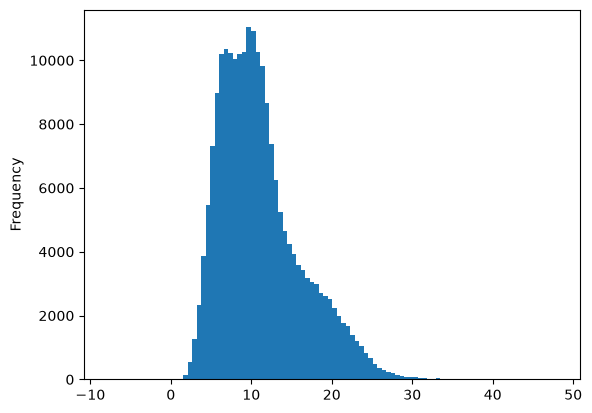

In [56]:
df['mean_llr_score'].plot.hist(bins=100)

<Axes: ylabel='Frequency'>

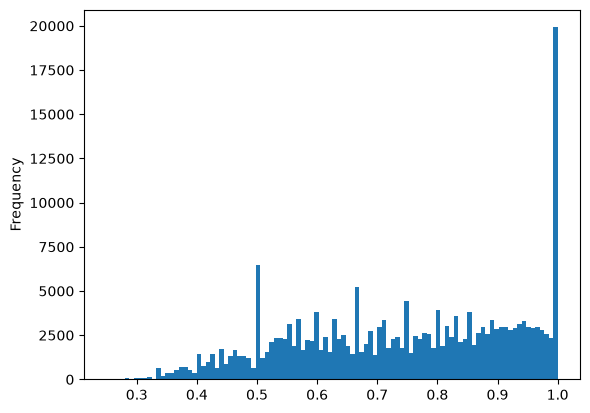

In [63]:
df['classification_confidence'].plot.hist(bins=100)

In [65]:
def threshold_numbers(df, th, field):
    df_filtered = df[df[field] > th]
    grouped = df_filtered.groupby(df.classification)['classification'].count()
    return grouped['WHISTLE'], grouped['BURST'], grouped['ECHO']


def threshold_length(df, th, field):
    df_filtered = df[df[field] > th].copy()
    df_filtered['length'] = df_filtered['stop_sample'] - df_filtered['start_sample']
    grouped = df_filtered.groupby(df.classification)['length'].mean() / 44100
    return grouped['WHISTLE'], grouped['BURST'], grouped['ECHO']


def statistics(func, df, field, thresholds):
    n_whistles = []
    n_burst = []
    n_echo = []
    for th in thresholds:
        w, b, e = func(df, th, field)
        n_whistles.append(w)
        n_burst.append(b)
        n_echo.append(e)
    return n_whistles, n_burst, n_echo

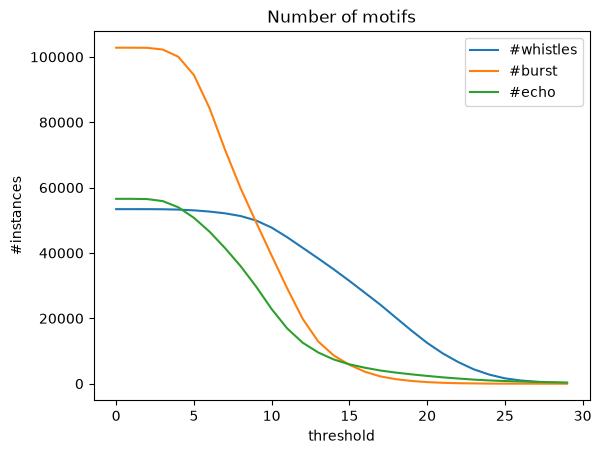

In [66]:
n_whistles, n_burst, n_echo = statistics(threshold_numbers, df, 'mean_llr_score', [i for i in range(0, 30)])
plt.plot(n_whistles, label='#whistles')
plt.plot(n_burst, label='#burst')
plt.plot(n_echo, label='#echo')
plt.legend()
plt.xlabel('threshold')
plt.ylabel('#instances')
plt.title('Number of motifs')
plt.show()

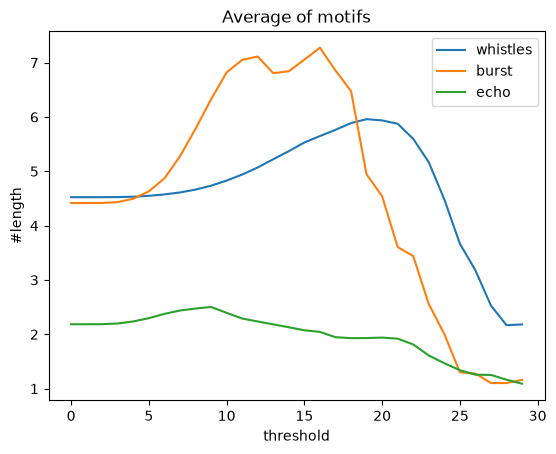

In [67]:
n_whistles, n_burst, n_echo = statistics(threshold_length, df, 'mean_llr_score', [i for i in range(0, 30)])
plt.plot(n_whistles, label='whistles')
plt.plot(n_burst, label='burst')
plt.plot(n_echo, label='echo')
plt.legend()
plt.xlabel('threshold')
plt.ylabel('#length')
plt.title('Average of motifs')
plt.show()

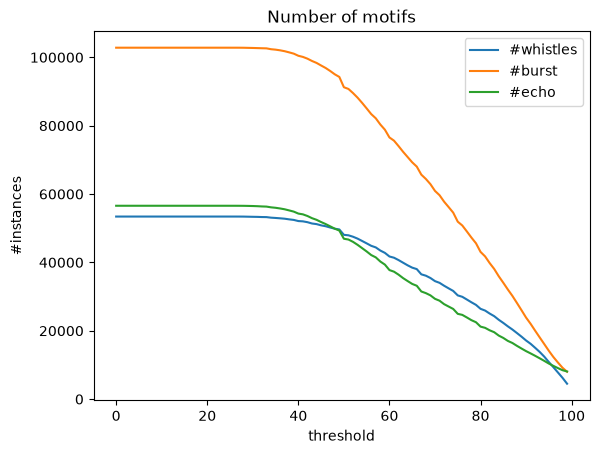

In [68]:
n_whistles, n_burst, n_echo = statistics(threshold_numbers, df, 'classification_confidence', [i / 100 for i in range(0,100)])
plt.plot(n_whistles, label='#whistles')
plt.plot(n_burst, label='#burst')
plt.plot(n_echo, label='#echo')
plt.legend()
plt.xlabel('threshold')
plt.ylabel('#instances')
plt.title('Number of motifs')
plt.show()

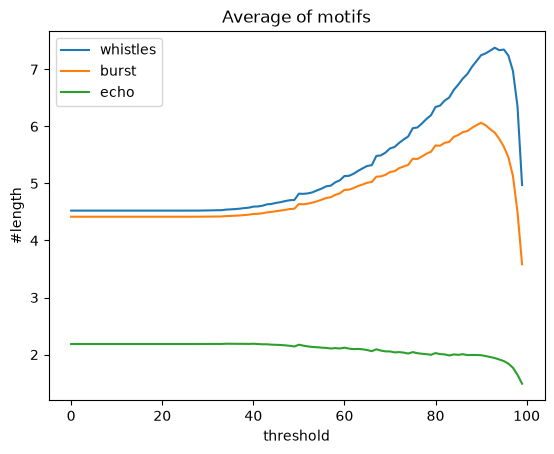

In [70]:
n_whistles, n_burst, n_echo = statistics(threshold_length, df, 'classification_confidence', [i / 100 for i in range(0,100)])
plt.plot(n_whistles, label='whistles')
plt.plot(n_burst, label='burst')
plt.plot(n_echo, label='echo')
plt.legend()
plt.xlabel('threshold')
plt.ylabel('#length')
plt.title('Average of motifs')
plt.show()

In [71]:
len(df)

212793

In [76]:
len(set(df['submodel_id']))

469

3802 393
212793 469


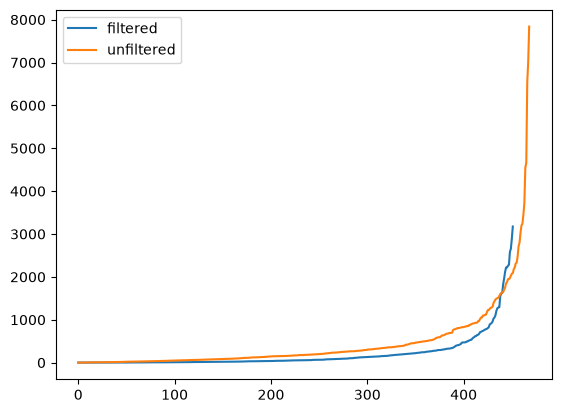

In [148]:
def threshold(x):
    if x < 5:
        return 0
    return min(x, 10)

counters = counts.apply(lambda x: threshold(x))
print(counters.sum(), len([1 for i in counters if i > 0]))
print(counts_unfiltered.sum(), len([1 for i in counts_unfiltered if i > 0]))

counts = df[df.classification_confidence >= 0.8].groupby('submodel_id')['submodel_id'].count()
plt.plot(sorted(counts), label = 'filtered')
counts_unfiltered = df.groupby('submodel_id')['submodel_id'].count()
plt.plot(sorted(counts_unfiltered), label = 'unfiltered')
plt.legend()
plt.show()



In [174]:
import heapq


N_INSTANCES = 15 
TH_CLASS = 0.8
selection = {submodel: [] for submodel in set(df['submodel_id'])}
for _, row in df.iterrows():
    if row['classification_confidence'] > TH_CLASS: 
        motif = row['submodel_id']
        if (len(selection[motif]) < N_INSTANCES) or (row['mean_llr_score'] > selection[motif][0][0]):
            if len(selection[motif]) < N_INSTANCES:
                heapq.heappush(selection[motif], (row['mean_llr_score'], row['results_id']))
            else:
                heapq.heappushpop(selection[motif], (row['mean_llr_score'], row['results_id']))
all_ids = []
for heap in selection.values():
    if len(heap) > 4:
        for _, results_id in heap:
            all_ids.append(results_id)
ids = set(all_ids)
df['keep'] = df['results_id'].apply(lambda x: x in ids)

In [180]:
df[df.keep]

,results_id,stem,wav_file,wav_file_id,hit_id,submodel_id,start_sample,stop_sample,sample_rate,start_time_s,...,region_start_s,region_offset_s,classification,classification_confidence,whistle_direction,mean_emission_score,mean_noise_score,mean_llr_score,embedding_model,keep
54,55,012894_SonyUW2,012894_SonyUW2.m4a,1SBG1rd-t0ZivLtTkTHaeSlkajUwg9186,149,290,16128000,16163840,44100,365.714286,...,365.214286,0.5,BURST,0.928571,NaN,39.095112,32.217868,6.877244,whisper,True
120,121,03198901_SonyUW,03198901_SonyUW.m4a,1S4aUE2CZm0js7GZe5zIUrx8ZeUwAswCj,56,17,6376960,6435840,44100,144.602268,...,144.102268,0.5,BURST,0.956522,NaN,39.127467,29.767857,9.359610,whisper,True
138,139,03198901_SonyUW,03198901_SonyUW.m4a,1S4aUE2CZm0js7GZe5zIUrx8ZeUwAswCj,102,17,14481920,14955520,44100,328.388209,...,327.888209,0.5,BURST,0.940541,NaN,40.156613,31.651123,8.505490,whisper,True
209,210,03218903_SonyUW,03218903_SonyUW.m4a,1lR52IHSKANUTmB5Gv5oOpbeo3ZUsuWMW,68,213,45450240,46405120,44100,1030.617687,...,1030.117687,0.5,BURST,1.000000,NaN,41.338390,23.616946,17.721444,whisper,True
224,225,03218903_SonyUW,03218903_SonyUW.m4a,1lR52IHSKANUTmB5Gv5oOpbeo3ZUsuWMW,89,467,51338240,51594240,44100,1164.132426,...,1163.632426,0.5,ECHO,0.840000,NaN,39.195741,33.326084,5.869657,whisper,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212711,213442,09259201_SonyUW,09259201_SonyUW.m4a,1JEvT0RDqeRM0jHmGbhq1HbdP-KPwgSkL,90,287,23493120,23813120,44100,532.723810,...,532.223810,0.5,WHISTLE,0.920000,DOWN,39.333225,23.064356,16.268868,whisper,True
212720,213451,09259201_SonyUW,09259201_SonyUW.m4a,1JEvT0RDqeRM0jHmGbhq1HbdP-KPwgSkL,99,468,25374720,25418240,44100,575.390476,...,574.890476,0.5,WHISTLE,0.941176,UP,38.803458,21.515600,17.287859,whisper,True
212722,213453,09259201_SonyUW,09259201_SonyUW.m4a,1JEvT0RDqeRM0jHmGbhq1HbdP-KPwgSkL,101,274,25569280,25679360,44100,579.802268,...,579.302268,0.5,WHISTLE,0.883721,DOWN,39.386294,25.787404,13.598891,whisper,True
212726,213457,09259201_SonyUW,09259201_SonyUW.m4a,1JEvT0RDqeRM0jHmGbhq1HbdP-KPwgSkL,105,274,26178560,26357760,44100,593.618141,...,593.118141,0.5,WHISTLE,0.985714,DOWN,39.503576,25.473091,14.030484,whisper,True


<Axes: ylabel='Frequency'>

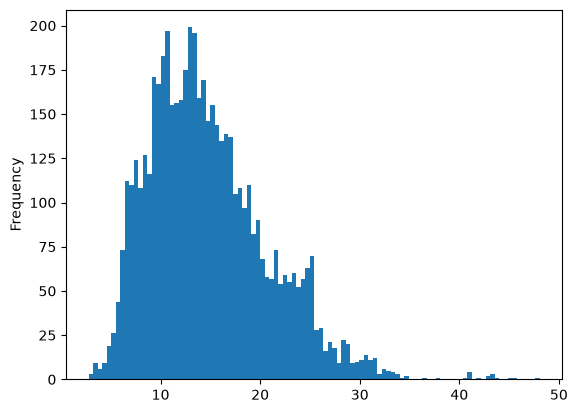

In [181]:
df[df.keep]['mean_llr_score'].plot.hist(bins=100)